# Løysingsforslag: tolke verdata

Oppgåvene brukar `utestasjon-bones.csv` (verstasjon ute på Øvre Kråkenes, 15. november – 4. desember 2022). Sjå `tolke-ute.ipynb`, `tolke-v2.ipynb` og `meir-eksempel.ipynb` for hjelp.

Kolonnar: `dato`, `temperatur` (°C), `lufttrykk` (hPa), `luftfuktighet` (%), `pm25` og `pm10` (µg/m³).

## Nivå 1 – Kom i gang

### Oppgåve 1
Les inn `utestasjon-bones.csv` med Pandas, slik at `dato` blir lesen som tidspunkt. Skriv ut kor mange målingar det er, og første og siste tidspunkt.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("utestasjon-bones.csv", parse_dates=["dato"])

print("Tal på målingar:", len(data))
print("Første:", data["dato"].min())
print("Siste:", data["dato"].max())

Tal på målingar: 42238
Første: 2022-11-15 18:59:55.540108
Siste: 2022-12-04 09:38:23.426802


### Oppgåve 2
Kva var gjennomsnittleg lufttrykk i perioden? Avrund til éin desimal.

In [2]:
print(round(data["lufttrykk"].mean(), 1), "hPa")

1010.5 hPa


### Oppgåve 3
Kor mange målingar har temperatur under 0 °C? Kor mange prosent av alle målingane er det?

In [3]:
under_null = data[data["temperatur"] < 0]
prosent = len(under_null) / len(data) * 100
print(f"{len(under_null)} målingar under 0 °C, det er {prosent:.1f} %")

4436 målingar under 0 °C, det er 10.5 %


### Oppgåve 4
Plott lufttrykket over heile perioden. Grafen skal ha tittel, og aksane skal ha namn med eining.

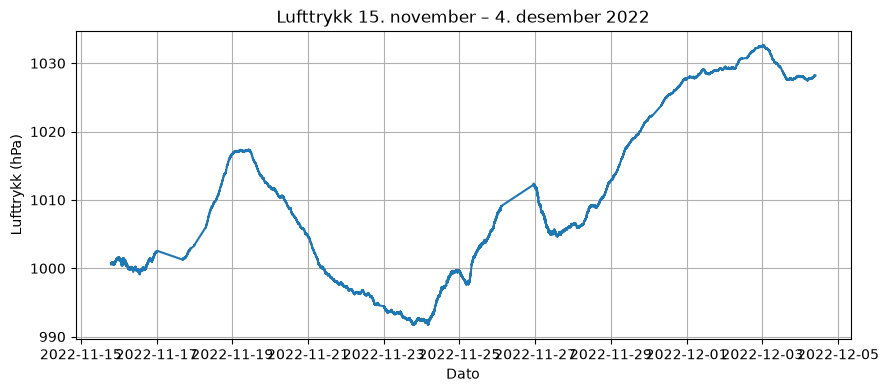

In [4]:
plt.figure(figsize=(10, 4))
plt.plot(data["dato"], data["lufttrykk"])
plt.title("Lufttrykk 15. november – 4. desember 2022")
plt.xlabel("Dato")
plt.ylabel("Lufttrykk (hPa)")
plt.grid()
plt.show()

## Nivå 2 – Litt meir krevjande

### Oppgåve 5
Finn høgaste og lågaste temperatur, og **når** dei vart målte.

*Tips:* `data["temperatur"].idxmax()` gir radnummeret til den høgaste verdien. Kva får du? Er alle verdiane til å stole på? (Sjå på dei første timane i dataa.)

In [5]:
rad_maks = data["temperatur"].idxmax()
rad_min = data["temperatur"].idxmin()
print("Høgast:", data.loc[rad_maks, "temperatur"], "°C, kl.", data.loc[rad_maks, "dato"])
print("Lågast:", data.loc[rad_min, "temperatur"], "°C, kl.", data.loc[rad_min, "dato"])

# Den høgaste verdien (26 °C) vart målt før stasjonen var sett ut.
# Fjernar me desse målingane, får me eit meir realistisk svar:
ute = data[data["dato"] >= "2022-11-15 19:45"]
rad_maks = ute["temperatur"].idxmax()
print("Høgast etter rydding:", ute.loc[rad_maks, "temperatur"], "°C, kl.", ute.loc[rad_maks, "dato"])

Høgast: 26.063973628074326 °C, kl. 2022-11-15 19:01:01.211174
Lågast: -2.8658273550017945 °C, kl. 2022-11-21 06:33:05.072478
Høgast etter rydding: 15.521467112950102 °C, kl. 2022-11-15 19:45:12.901593


### Oppgåve 6
Plott temperaturen for 20. november. Kva tid på døgnet var det kaldast?

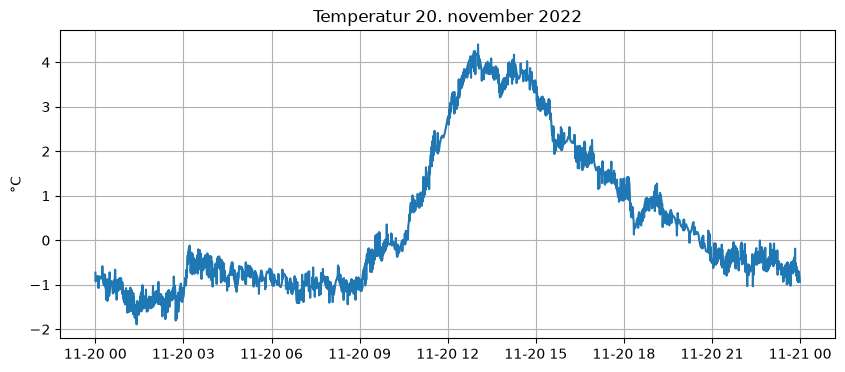

Kaldast: -1.8908360620814886 °C, kl. 01:24


In [6]:
dag = data[(data["dato"] >= "2022-11-20") & (data["dato"] < "2022-11-21")]

plt.figure(figsize=(10, 4))
plt.plot(dag["dato"], dag["temperatur"])
plt.title("Temperatur 20. november 2022")
plt.ylabel("°C")
plt.grid()
plt.show()

kaldast = dag.loc[dag["temperatur"].idxmin()]
print("Kaldast:", kaldast["temperatur"], "°C, kl.", kaldast["dato"].strftime("%H:%M"))

### Oppgåve 7
`pm10` er alle partiklar mindre enn 10 µm, så `pm10` inkluderer `pm25`. Lag ei ny kolonne `pm_grov` med partiklar mellom 2,5 og 10 µm (`pm10 - pm25`). Kva er snittet av `pm_grov`?

In [7]:
data["pm_grov"] = data["pm10"] - data["pm25"]
print(f"Snitt pm_grov: {data['pm_grov'].mean():.1f} µg/m³")

Snitt pm_grov: 3.3 µg/m³


### Oppgåve 8
Rekn ut gjennomsnittstemperaturen for kvart døgn. Bruk berre målingane frå etter at stasjonen vart sett ut (sjå oppgåve 5). Kva døgn var varmast, og kva døgn var kaldast? Er det nokre døgn du ikkje bør stole heilt på?

*Tips:* Gjer `dato` om til indeks med `data.set_index("dato")`, og bruk `resample("D")`. Med `.agg(["mean", "count"])` får du òg talet på målingar kvart døgn.

In [8]:
ute = data[data["dato"] >= "2022-11-15 19:45"]
dogn = ute.set_index("dato")["temperatur"].resample("D").agg(["mean", "count"])
print(dogn.round(1))

# Eit fullt døgn har rundt 2600 målingar. Døgn med mykje færre målingar
# (til dømes 15.11, 17.11, 26.11 og 4.12) manglar data, så snittet er usikkert.
# Me tek difor berre med døgn med minst 2000 målingar:
dogn = dogn[dogn["count"] >= 2000]["mean"]
print("Varmast:", dogn.idxmax().date(), f"({dogn.max():.1f} °C)")
print("Kaldast:", dogn.idxmin().date(), f"({dogn.min():.1f} °C)")

            mean  count
dato                   
2022-11-15  11.7    465
2022-11-16  11.0   2622
2022-11-17   6.0    630
2022-11-18   4.3   1840
2022-11-19   1.5   2621
2022-11-20   0.4   2621
2022-11-21   1.3   2615
2022-11-22   3.2   2286
2022-11-23   8.3   2600
2022-11-24  10.4   2622
2022-11-25  11.1   2623
2022-11-26  10.4    398
2022-11-27  10.6   2623
2022-11-28  10.7   2621
2022-11-29   9.2   2622
2022-11-30   7.4   2005
2022-12-01   6.4   2616
2022-12-02   2.4   2109
2022-12-03   1.0   2622
2022-12-04  -1.2   1050
Varmast: 2022-11-25 (11.1 °C)
Kaldast: 2022-11-20 (0.4 °C)


## Nivå 3 – Utfordringar

### Oppgåve 9
Verdas helseorganisasjon (WHO) tilrår at døgnsnittet av PM2.5 ikkje bør vere over 15 µg/m³, og at døgnsnittet av PM10 ikkje bør vere over 45 µg/m³. Kva døgn vart grensene overskridne? Lag eit søylediagram av døgnsnittet for PM2.5 med ei vassrett linje for grensa (`plt.axhline`).

Døgn over PM2.5-grensa:
dato
2022-11-17    44.6
2022-11-18    23.3
2022-11-19    22.7
2022-11-20    35.1
2022-11-30    18.0
2022-12-02    21.9
2022-12-03    32.3
Name: pm25, dtype: float64

Døgn over PM10-grensa:
dato
2022-11-17    57.6
2022-11-20    46.2
Freq: 3D, Name: pm10, dtype: float64


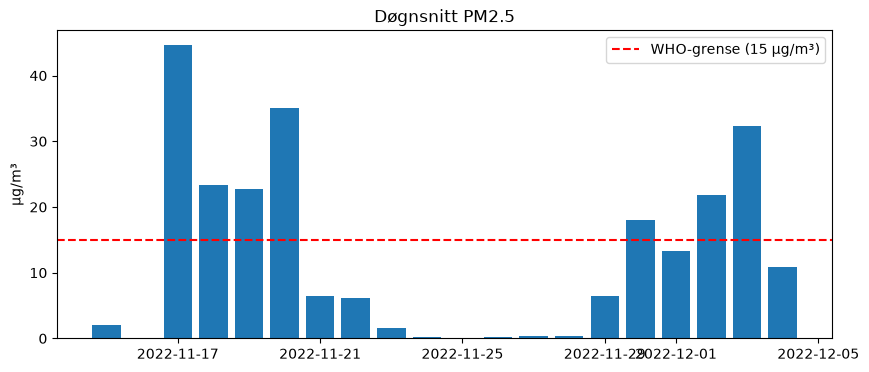

In [9]:
dogn_pm = data.set_index("dato")[["pm25", "pm10"]].resample("D").mean()

print("Døgn over PM2.5-grensa:")
print(dogn_pm[dogn_pm["pm25"] > 15]["pm25"].round(1))
print("\nDøgn over PM10-grensa:")
print(dogn_pm[dogn_pm["pm10"] > 45]["pm10"].round(1))

plt.figure(figsize=(10, 4))
plt.bar(dogn_pm.index, dogn_pm["pm25"])
plt.axhline(15, color="red", linestyle="--", label="WHO-grense (15 µg/m³)")
plt.title("Døgnsnitt PM2.5")
plt.ylabel("µg/m³")
plt.legend()
plt.show()

### Oppgåve 10
Når lufttrykket fell raskt, kjem det ofte dårleg vêr. Finn den største endringa i lufttrykk over tre timar. Når skjedde det?

*Tips:* Lag timesnitt med `resample("60min").mean()`, og bruk `diff(3)` for å finne endringa frå tre timar før.

Største fall: -2.9 hPa, tre timar fram til 2022-11-27 03:00:00
Største auke: 3.3 hPa, tre timar fram til 2022-11-25 08:00:00


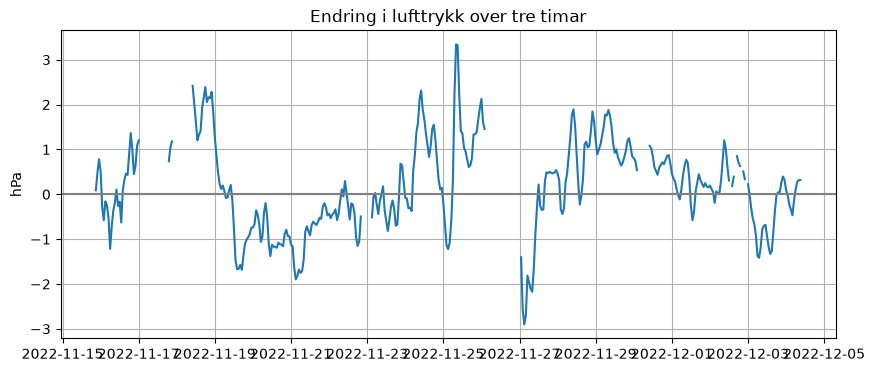

In [10]:
trykk_time = data.set_index("dato")["lufttrykk"].resample("60min").mean()
endring = trykk_time.diff(3)  # Endring sidan tre timar før

print(f"Største fall: {endring.min():.1f} hPa, tre timar fram til {endring.idxmin()}")
print(f"Største auke: {endring.max():.1f} hPa, tre timar fram til {endring.idxmax()}")

plt.figure(figsize=(10, 4))
plt.plot(endring.index, endring)
plt.axhline(0, color="gray")
plt.title("Endring i lufttrykk over tre timar")
plt.ylabel("hPa")
plt.grid()
plt.show()

### Oppgåve 11
Utan Pandas: Bruk `csv`-biblioteket til å rekne ut gjennomsnittstemperaturen. Får du same svar som med `data["temperatur"].mean()`?

In [11]:
import csv

summ = 0
tal = 0
with open("utestasjon-bones.csv", encoding="utf-8-sig") as fil:
    filinnhald = csv.reader(fil)
    next(filinnhald)  # Hoppar over overskriftene
    for rad in filinnhald:
        summ += float(rad[1])  # Temperatur er kolonne nr. 1 (teljinga startar på 0)
        tal += 1

print(f"Med csv:    {summ / tal:.4f} °C")
print(f"Med Pandas: {data['temperatur'].mean():.4f} °C")

Med csv:    6.2173 °C


Med Pandas: 6.2173 °C


### Oppgåve 12 – Datadetektiv
Fila `data.csv` inneheld **ikkje** ekte målingar, men tilfeldig genererte tal. Finn bevis for dette! Plott dataa, og sjå på kor mykje verdiane endrar seg frå éi måling til den neste. Er det fysisk mogleg?

                        tidspunkt  temperatur  luftfuktighet  lufttrykk  \
count                          49        49.0           49.0       49.0   
mean   2023-10-05 08:24:15.592783        10.8           51.8     1006.9   
min    2023-10-05 08:22:15.408369        -9.9            4.9      901.5   
25%    2023-10-05 08:23:15.494105         2.5           35.6      962.2   
50%    2023-10-05 08:24:15.597097        10.8           46.2     1011.9   
75%    2023-10-05 08:25:15.679205        21.0           75.4     1059.8   
max    2023-10-05 08:26:15.779296        29.6           99.0     1099.3   
std                           NaN        11.1           26.0       61.7   

       partikkelkonsentrasjon  
count                    49.0  
mean                    426.8  
min                      17.0  
25%                     224.0  
50%                     377.6  
75%                     640.6  
max                     995.1  
std                     281.7  

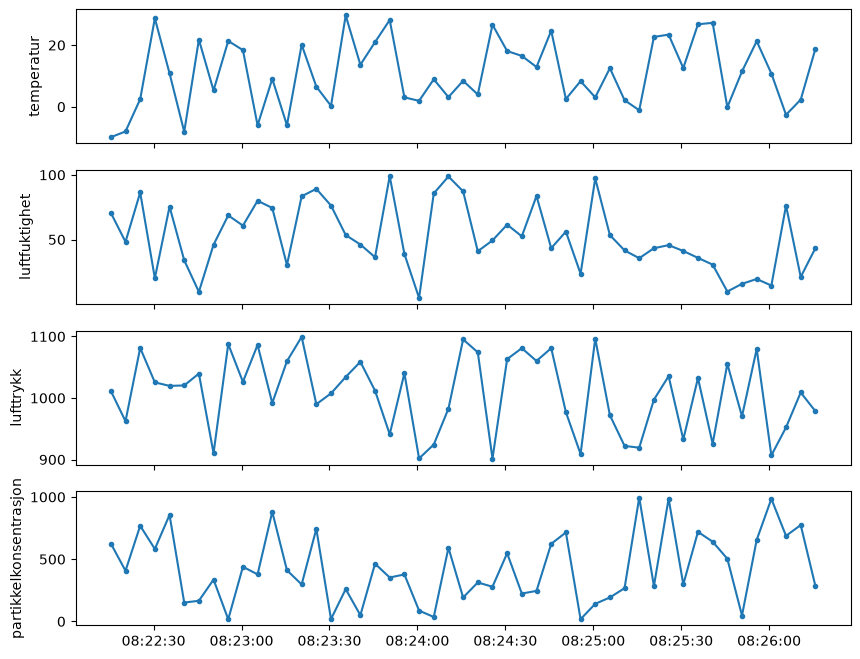

Største temperaturendring mellom to målingar: 29.9 °C
Største trykkendring mellom to målingar: 187.5 hPa


In [12]:
falsk = pd.read_csv("data.csv", parse_dates=["tidspunkt"])
print(falsk.describe().round(1))

fig, axes = plt.subplots(4, 1, sharex=True, figsize=(10, 8))
for ax, kolonne in zip(axes, ["temperatur", "luftfuktighet", "lufttrykk", "partikkelkonsentrasjon"]):
    ax.plot(falsk["tidspunkt"], falsk[kolonne], marker=".")
    ax.set_ylabel(kolonne)
plt.show()

# Endring mellom målingar som berre er rundt 5 sekund frå kvarandre:
print("Største temperaturendring mellom to målingar:", round(falsk["temperatur"].diff().abs().max(), 1), "°C")
print("Største trykkendring mellom to målingar:", round(falsk["lufttrykk"].diff().abs().max(), 1), "hPa")

# Temperaturen hoppar fleire tital grader og lufttrykket over 100 hPa på nokre sekund.
# Det skjer ikkje i verkelegheita, der endrar slike storleikar seg gradvis.
# I ekte data heng også ei måling saman med den førre (sjå tolke-ute.ipynb).

### Oppgåve 13 – Refleksjon
Gjennomsnittleg luftfukt ute er berre rundt 36 %, men utandørs i november på Vestlandet er luftfukta vanlegvis 80–90 %. Kva kan vere årsaka? Sjå på kva du veit om korleis temperatursensoren blir varma opp av Raspberry Pi-en (sjå `README.md` i `verstasjon`-mappa).

In [13]:
# Sensoren blir varma opp av prosessoren på Raspberry Pi-en. Relativ luftfukt
# seier kor mykje vassdamp lufta inneheld samanlikna med kor mykje ho KAN innehalde.
# Varm luft kan innehalde meir vassdamp, så når lufta rundt sensoren er varmare
# enn lufta ute, blir den relative luftfukta målt for lågt.
# Temperaturen blir korrigert i programmet, men luftfukta blir ikkje det.
# Løysingar: flytte sensoren vekk frå Pi-en med ein kabel, eller rekne ut
# korrigert luftfukt frå den korrigerte temperaturen.
print("Snitt luftfukt:", round(data["luftfuktighet"].mean(), 1), "%")

Snitt luftfukt: 35.8 %
